# 01 — Dataset audit (Week 1, read-only)

**Project:** NBA All-Star prediction — ML-2026, ESILV · **Module 2 (EDA & statistical tests)** — owner: Augustin Nilsson, reviewer: Basile Chabrel

**Dataset:** Kaggle `sumitrodatta/nba-aba-baa-stats`, pinned version 57 (downloaded by `python -m src.data.download`).

**Rules of this notebook**
- Read-only: no row is dropped, no value is imputed or transformed, no season filter is applied, nothing is written to `data/`.
- Joins and group-bys are done in memory only, to *inspect* the data.
- Outputs: figures in `report/figures/`, tables in `report/tables/`, and every number quoted in the Week 1 PDF in `report/audit_numbers.json`.
- Decisions (season range, traded players, prediction time, injury replacements) are **flagged, not made**.

In [1]:
# --- Setup -------------------------------------------------------------------
import json
import platform
import sys
from pathlib import Path

# Make the project root importable whether the notebook runs from notebooks/ or the root
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import (AUDIT_NUMBERS_PATH, FIGURE_DPI, FIGURES_DIR, KAGGLE_DATASET,
                        KAGGLE_VERSION, RAW_FILES_DIR, RAW_MANIFEST_PATH, SEED, TABLES_DIR,
                        ensure_dirs)
from src.data.download import sha256_of
from src.eda import audit

np.random.seed(SEED)  # this notebook uses no randomness; seed set for project consistency
ensure_dirs()
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

AUDIT = {}  # every number that the PDF quotes is stored here, then saved to JSON

print("Python", platform.python_version(), "| pandas", pd.__version__,
      "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)

Python 3.14.2 | pandas 3.1.1 | numpy 2.5.5 | matplotlib 3.11.2


In [2]:
# --- Check that we audit exactly the pinned files listed in the manifest -------
manifest = json.loads(RAW_MANIFEST_PATH.read_text(encoding="utf-8"))
mismatches = [name for name, info in manifest["files"].items()
              if sha256_of(RAW_FILES_DIR / name) != info["sha256"]]
assert manifest["version"] == KAGGLE_VERSION and not mismatches, mismatches
print(f"{manifest['dataset']} v{manifest['version']}: {len(manifest['files'])} files, all checksums OK")
AUDIT["source"] = {"dataset": KAGGLE_DATASET, "version": KAGGLE_VERSION,
                   "zip_sha256": manifest["zip_sha256"], "n_files": len(manifest["files"]),
                   "license": manifest["license"]}

sumitrodatta/nba-aba-baa-stats v57: 22 files, all checksums OK


## 1. Load and inspect

In [3]:
# Load every CSV of the dataset (read-only)
tables = {path.name: pd.read_csv(path) for path in sorted(RAW_FILES_DIR.glob("*.csv"))}
overview = pd.DataFrame([
    {"file": name, "rows": len(df), "columns": df.shape[1],
     "memory_MB": round(df.memory_usage(deep=True).sum() / 1e6, 2),
     "seasons": f"{df.season.min()}-{df.season.max()}" if "season" in df else "-"}
    for name, df in tables.items()
])
overview

,file,rows,columns,memory_MB,seasons
0,Advanced.csv,33780,30,16.02,1947-2027
1,All-Star Selections.csv,2058,6,0.48,1951-2026
2,Draft Pick History.csv,8443,8,2.59,1947-2026
3,End of Season Teams (Voting).csv,4484,14,1.76,1963-2025
4,End of Season Teams.csv,2222,7,0.73,1947-2025
5,Opponent Stats Per 100 Poss.csv,1492,28,0.54,1974-2027
6,Opponent Stats Per Game.csv,1938,28,0.70,1947-2027
7,Opponent Totals.csv,1938,28,0.70,1947-2027
8,Per 100 Poss.csv,28133,34,14.27,1974-2027
9,Per 36 Minutes.csv,32697,32,16.05,1952-2027


In [4]:
# The 5 tables used to define the unit of analysis, the features and the label
per_game = tables["Player Per Game.csv"]
totals = tables["Player Totals.csv"]
advanced = tables["Advanced.csv"]
info = tables["Player Season Info.csv"]
asg = tables["All-Star Selections.csv"]

for name, df in [("Player Per Game", per_game), ("Player Totals", totals),
                 ("Advanced", advanced), ("Player Season Info", info), ("All-Star Selections", asg)]:
    print(f"{name:20s} shape={df.shape}  memory={df.memory_usage(deep=True).sum()/1e6:.1f} MB  "
          f"dtypes={df.dtypes.astype(str).value_counts().to_dict()}")

AUDIT["shapes"] = {name: list(df.shape) for name, df in tables.items()}
AUDIT["n_player_rows"] = len(totals)
AUDIT["season_min"], AUDIT["season_max"] = int(totals.season.min()), int(totals.season.max())
AUDIT["rows_by_league"] = totals.lg.value_counts().to_dict()
AUDIT["label_rows"] = len(asg)
AUDIT["label_rows_by_league"] = asg.lg.value_counts().to_dict()
AUDIT["label_season_min"], AUDIT["label_season_max"] = int(asg.season.min()), int(asg.season.max())

Player Per Game      shape=(33780, 32)  memory=16.6 MB  dtypes={'float64': 25, 'str': 5, 'int64': 2}
Player Totals        shape=(33780, 33)  memory=16.8 MB  dtypes={'float64': 20, 'int64': 8, 'str': 5}
Advanced             shape=(33780, 30)  memory=16.0 MB  dtypes={'float64': 23, 'str': 5, 'int64': 2}
Player Season Info   shape=(33780, 8)  memory=10.1 MB  dtypes={'str': 5, 'int64': 2, 'float64': 1}
All-Star Selections  shape=(2058, 6)  memory=0.5 MB  dtypes={'str': 4, 'int64': 1, 'bool': 1}


In [5]:
# First rows: note `season` is the END year of the season (2024 = 2023-24)
display(totals.head(3))
display(advanced.head(3))
display(asg.head(3))

,season,lg,player,player_id,age,team,pos,g,gs,mp,fg,fga,fg_percent,x3p,x3pa,x3p_percent,x2p,x2pa,x2p_percent,e_fg_percent,ft,fta,ft_percent,orb,drb,trb,ast,stl,blk,tov,pf,pts,trp_dbl
0,2027,NBA,Precious Achiuwa,achiupr01,27.0,SAC,C,6,4.0,173.0,34,61,0.557,1.0,5.0,0.200,33.0,56.0,0.589,0.566,6,16,0.375,12.0,24.0,36.0,6,11.0,5.0,6.0,13.0,75,0.0
1,2027,NBA,Darius Acuff Jr.,acuffda01,20.0,SAC,PG,6,6.0,219.0,57,144,0.396,19.0,59.0,0.322,38.0,85.0,0.447,0.462,25,29,0.862,2.0,20.0,22.0,38,3.0,1.0,20.0,18.0,158,0.0
2,2027,NBA,Steven Adams,adamsst01,33.0,HOU,C,1,0.0,9.0,2,2,1.000,0.0,0.0,NaN,2.0,2.0,1.000,1.000,0,0,NaN,1.0,1.0,2.0,1,1.0,0.0,0.0,4.0,4,0.0


,season,lg,player,player_id,age,team,pos,g,gs,mp,per,ts_percent,x3p_ar,f_tr,orb_percent,drb_percent,trb_percent,ast_percent,stl_percent,blk_percent,tov_percent,usg_percent,ows,dws,ws,ws_48,obpm,dbpm,bpm,vorp
0,2027,NBA,Precious Achiuwa,achiupr01,27.0,SAC,C,6,4.0,173.0,15.6,0.551,0.082,0.262,7.2,16.9,11.6,5.4,2.9,2.7,8.1,17.6,0.1,0.0,0.1,0.037,-0.4,-1.0,-1.5,0.0
1,2027,NBA,Darius Acuff Jr.,acuffda01,20.0,SAC,PG,6,6.0,219.0,14.4,0.504,0.410,0.201,0.9,11.1,5.6,29.7,0.6,0.4,11.3,33.2,-0.1,-0.1,-0.3,-0.055,1.1,-4.6,-3.5,-0.1
2,2027,NBA,Steven Adams,adamsst01,33.0,HOU,C,1,0.0,9.0,23.9,1.000,0.000,0.000,13.3,12.0,12.6,16.7,5.4,0.0,0.0,9.4,0.1,0.0,0.1,0.379,1.7,6.2,7.9,0.0


,player,player_id,team,season,lg,replaced
0,Scottie Barnes,barnesc01,Team Stars,2026,NBA,False
1,Devin Booker,bookede01,Team Stars,2026,NBA,False
2,Cade Cunningham,cunnica01,Team Stars,2026,NBA,False


In [6]:
# Column types of the main stat table (non-numeric columns are the identifiers)
print("Non-numeric columns in Player Totals:", totals.select_dtypes(exclude="number").columns.tolist())
print("Non-numeric columns in Advanced:", advanced.select_dtypes(exclude="number").columns.tolist())
print("All-Star Selections dtypes:", asg.dtypes.astype(str).to_dict())

Non-numeric columns in Player Totals: ['lg', 'player', 'player_id', 'team', 'pos']
Non-numeric columns in Advanced: ['lg', 'player', 'player_id', 'team', 'pos']
All-Star Selections dtypes: {'player': 'str', 'player_id': 'str', 'team': 'str', 'season': 'int64', 'lg': 'str', 'replaced': 'bool'}


## 2. Missingness

First the raw count and percentage per column, then a **structural explanation** of each missing cell
(rules in `src/eda/audit.py::explain_missing`):
1. the denominator of a percentage/rate is not recorded → *not recorded in era*;
2. the denominator is 0 (e.g. 3P% with 0 three-point attempts) → *zero denominator*;
3. the column is recorded for < 50% of rows in that league-season → *not recorded in era*;
4. anything else → *unexplained* (candidate random / data-quality missingness).

Nothing is imputed.

In [7]:
miss = pd.concat([
    audit.missingness_table(per_game, "Player Per Game"),
    audit.missingness_table(totals, "Player Totals"),
    audit.missingness_table(advanced, "Advanced"),
    audit.missingness_table(info, "Player Season Info"),
    audit.missingness_table(asg, "All-Star Selections"),
], ignore_index=True)
miss.to_csv(TABLES_DIR / "missingness_raw.csv", index=False)
print("Columns with no missing value at all are not listed.")
miss.sort_values(["table", "pct_missing"], ascending=[True, False])

Columns with no missing value at all are not listed.


,table,column,n_missing,pct_missing
43,Advanced,gs,8155,24.14
47,Advanced,x3p_ar,6511,19.27
55,Advanced,tov_percent,5752,17.03
61,Advanced,obpm,5653,16.73
62,Advanced,dbpm,5653,16.73
...,...,...,...,...
35,Player Totals,trb,894,2.65
24,Player Totals,fg_percent,177,0.52
20,Player Totals,age,20,0.06
40,Player Totals,trp_dbl,5,0.01


In [8]:
# In-memory view: totals + advanced metrics of the SAME row (key = player, season, league, team)
for name, df in [("totals", totals), ("advanced", advanced), ("per_game", per_game), ("info", info)]:
    assert not df.duplicated(audit.ROW_KEY).any(), f"{name}: row key not unique"
same_keys = (set(map(tuple, totals[audit.ROW_KEY].values)) == set(map(tuple, advanced[audit.ROW_KEY].values))
             == set(map(tuple, per_game[audit.ROW_KEY].values)) == set(map(tuple, info[audit.ROW_KEY].values)))
print("Row key (player_id, season, lg, team) unique in all 4 player tables:", True)
print("The 4 player tables contain exactly the same row keys:", same_keys)
AUDIT["player_tables_same_row_keys"] = bool(same_keys)

advanced_only = [c for c in advanced.columns if c not in totals.columns]
core = totals.merge(advanced[audit.ROW_KEY + advanced_only], on=audit.ROW_KEY, how="left", validate="one_to_one")

cols_with_nan = [c for c in core.columns if core[c].isna().any()]
structural = audit.structural_summary(core, cols_with_nan, mp_based_columns=set(advanced_only))
structural.to_csv(TABLES_DIR / "missingness_structural.csv", index=False)
structural

Row key (player_id, season, lg, team) unique in all 4 player tables:

 True
The 4 player tables contain exactly the same row keys: True


,column,n_missing,not_recorded_in_era,zero_denominator,unexplained,last_season_with_missing
0,age,20,0,0,20,1973
1,pos,1197,875,0,322,2026
2,gs,8155,8155,0,0,1981
3,mp,1083,1083,0,0,1951
4,fg_percent,177,0,177,0,2027
5,x3p,6352,6352,0,0,1979
6,x3pa,6353,6352,0,1,1979
7,x3p_percent,10690,6353,4337,0,2027
8,x2p,6352,6352,0,0,1979
9,x2pa,6352,6352,0,0,1979


In [9]:
unexplained_total = int(structural.unexplained.sum())
AUDIT["missing_structural"] = {
    "n_columns_with_missing": len(cols_with_nan),
    "cells_missing": int(structural.n_missing.sum()),
    "cells_not_recorded_in_era": int(structural.not_recorded_in_era.sum()),
    "cells_zero_denominator": int(structural.zero_denominator.sum()),
    "cells_unexplained": unexplained_total,
    "by_column": structural.set_index("column").to_dict(orient="index"),
}
print({k: v for k, v in AUDIT["missing_structural"].items() if k != "by_column"})

# Inspect the unexplained cells, if any: which columns, which seasons
unexpl_cols = structural.loc[structural.unexplained > 0, "column"].tolist()
for col in unexpl_cols:
    reason = audit.explain_missing(core, col, mp_based=col in advanced_only)
    rows = core.loc[reason == "unexplained", ["player", "season", "lg", "team", "g", "mp", col]]
    seasons = sorted(int(s) for s in rows.season.unique())
    print(f"\n{col}: {len(rows)} unexplained missing cells | seasons {seasons[:10]}{' ...' if len(seasons) > 10 else ''}"
          f" | top league-teams {rows.groupby(['lg', 'team']).size().nlargest(3).to_dict()}")
    display(rows.head(3))

{'n_columns_with_missing': 41, 'cells_missing': 159669, 'cells_not_recorded_in_era': 152138, 'cells_zero_denominator': 7121, 'cells_unexplained': 410}

age: 20 unexplained missing cells | seasons [1968, 1969, 1970, 1971, 1973] | top league-teams {('ABA', 'ANA'): 4, ('ABA', 'DNR'): 4, ('ABA', '2TM'): 2}


,player,season,lg,team,g,mp,age
28478,Pete Smith,1973,ABA,SDA,5,32.0,NaN
29075,Clarence Brookins,1971,ABA,FLO,8,59.0,NaN
29450,Jim Wilson,1971,ABA,PTC,6,44.0,NaN



pos: 322 unexplained missing cells | seasons [1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960, 1961] ... | top league-teams {('NBA', 'NYK'): 26, ('NBA', '2TM'): 25, ('NBA', 'BLB'): 20}


,player,season,lg,team,g,mp,pos
665,Hayden Gray,2026,NBA,UTA,1,25.0,NaN
28610,Frank Card,1972,ABA,CAR,9,141.0,NaN
28664,Ron Dorsey,1972,ABA,CAR,1,12.0,NaN



x3pa: 1 unexplained missing cells | seasons [1971] | top league-teams {('ABA', 'VIR'): 1}


,player,season,lg,team,g,mp,x3pa
29397,Ron Taylor,1971,ABA,VIR,1,4.0,NaN


... (20 outputs left out)


ws: 11 unexplained missing cells | seasons [1955] | top league-teams {('NBA', 'BLB'): 11}


,player,season,lg,team,g,mp,ws
32167,Rollen Hans,1955,NBA,BLB,13,178.0,NaN
32171,Don Henriksen,1955,NBA,BLB,14,429.0,NaN
32177,Paul Hoffman,1955,NBA,BLB,9,281.0,NaN



ws_48: 11 unexplained missing cells | seasons [1955] | top league-teams {('NBA', 'BLB'): 11}


,player,season,lg,team,g,mp,ws_48
32167,Rollen Hans,1955,NBA,BLB,13,178.0,NaN
32171,Don Henriksen,1955,NBA,BLB,14,429.0,NaN
32177,Paul Hoffman,1955,NBA,BLB,9,281.0,NaN


In [10]:
# Descriptive only (not a filter): how many unexplained cells fall in the NBA 3-point era (1980-2026)?
modern = (core.lg == "NBA") & core.season.between(1980, 2026)
unexpl_modern = {col: int(((audit.explain_missing(core, col, mp_based=col in advanced_only) == "unexplained") & modern).sum())
                 for col in unexpl_cols}
unexpl_modern = {c: n for c, n in unexpl_modern.items() if n}
AUDIT["unexplained_missing_NBA_1980_2026"] = unexpl_modern
print("Unexplained missing cells, NBA 1980-2026:", unexpl_modern)

Unexplained missing cells, NBA 1980-2026: {'pos': 1, 'trp_dbl': 1}


In [11]:
# When does each statistic start being recorded? (first season with >= 50% of rows non-missing)
era_cols = ["mp", "gs", "orb", "drb", "stl", "blk", "tov", "x3pa", "per", "usg_percent", "bpm", "vorp", "ws"]
first_season = pd.DataFrame({
    lg: {c: audit.first_recorded_season(core, c, lg) for c in era_cols} for lg in ["BAA", "NBA", "ABA"]
})
AUDIT["first_recorded_season_NBA"] = first_season["NBA"].to_dict()
first_season

,BAA,NBA,ABA
mp,NaN,1952,1968.0
gs,NaN,1982,NaN
orb,NaN,1974,1969.0
drb,NaN,1974,1969.0
stl,NaN,1974,1974.0
blk,NaN,1974,1974.0
tov,NaN,1978,1968.0
x3pa,NaN,1980,1968.0
per,NaN,1952,1968.0
usg_percent,NaN,1978,1968.0


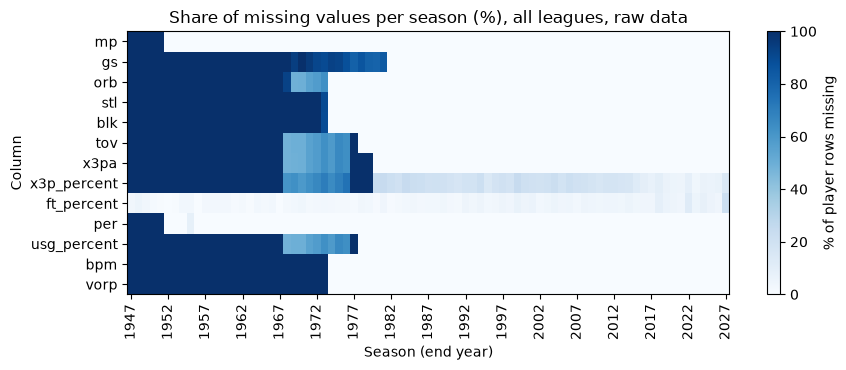

In [12]:
# Figure 1: share of missing values per season (all leagues pooled), selected columns
heat_cols = ["mp", "gs", "orb", "stl", "blk", "tov", "x3pa", "x3p_percent", "ft_percent", "per", "usg_percent", "bpm", "vorp"]
share_missing = core[heat_cols].isna().groupby(core["season"]).mean().T * 100

fig, ax = plt.subplots(figsize=(9, 3.8))
im = ax.imshow(share_missing.values, aspect="auto", cmap="Blues", vmin=0, vmax=100)
seasons = share_missing.columns.to_numpy()
tick_idx = np.arange(0, len(seasons), 5)
ax.set_xticks(tick_idx, seasons[tick_idx], rotation=90)
ax.set_yticks(range(len(heat_cols)), heat_cols)
ax.set_xlabel("Season (end year)")
ax.set_ylabel("Column")
ax.set_title("Share of missing values per season (%), all leagues, raw data")
fig.colorbar(im, ax=ax, label="% of player rows missing")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig1_missingness_by_season.png", dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()

## 3. Duplicates and key integrity

In [13]:
dup = pd.DataFrame([{"table": name, "exact_duplicate_rows": int(df.duplicated().sum())}
                    for name, df in tables.items()])
AUDIT["exact_duplicate_rows_total"] = int(dup.exact_duplicate_rows.sum())
print("Exact duplicate rows over all 22 files:", AUDIT["exact_duplicate_rows_total"])

traded = audit.traded_player_structure(totals)
AUDIT["traded"] = traded
traded

Exact duplicate rows over all 22 files: 0


{'n_rows_total': 33780,
 'n_rows_combined_code': 3052,
 'combined_codes': ['2TM', '3TM', '4TM', '5TM'],
 'n_rows_TOT_code': 0,
 'n_player_seasons_traded': 3052,
 'n_rows_in_traded_groups': 9380,
 'n_groups_without_exactly_one_combined_row': 0,
 'n_groups_digit_mismatch': 0,
 'n_groups_combined_games_ne_sum_of_team_games': 0,
 'n_single_row_with_combined_code': 0}

In [14]:
# Example: a player with the largest number of team rows in one season
multi_counts = totals.groupby(audit.PLAYER_SEASON_KEY).size()
example_key = multi_counts.sort_values(ascending=False).index[0]
example = totals.set_index(audit.PLAYER_SEASON_KEY).loc[[example_key]].reset_index()
example[["player", "season", "lg", "team", "g", "mp", "pts"]]

,player,season,lg,team,g,mp,pts
0,Bobby Jones,2008,NBA,5TM,47,531.0,178
1,Bobby Jones,2008,NBA,DEN,25,222.0,84
2,Bobby Jones,2008,NBA,MEM,9,137.0,40
3,Bobby Jones,2008,NBA,HOU,4,9.0,4
4,Bobby Jones,2008,NBA,MIA,6,143.0,48
5,Bobby Jones,2008,NBA,SAS,3,20.0,2


In [15]:
# Share of player-seasons that involve a trade, per decade (does the issue grow over time?)
ps = totals[audit.PLAYER_SEASON_KEY].drop_duplicates()
n_rows_ps = totals.groupby(audit.PLAYER_SEASON_KEY).size().rename("n_rows").reset_index()
n_rows_ps["decade"] = (n_rows_ps.season // 10) * 10
traded_share = (n_rows_ps.assign(traded=n_rows_ps.n_rows > 1)
                .groupby("decade").traded.mean().mul(100).round(1))
AUDIT["n_player_seasons"] = len(ps)
AUDIT["traded_share_pct_by_decade"] = traded_share.to_dict()
print("Unique player-seasons (player_id, season, lg):", len(ps))
traded_share.to_frame("% of player-seasons with a trade")

Unique player-seasons (player_id, season, lg): 27452


,% of player-seasons with a trade
decade,
1940,16.1
1950,12.5
1960,9.8
1970,11.1
1980,9.3
1990,9.5
2000,10.6
2010,12.8
2020,12.3


In [16]:
# Identity checks: one name per id? homonyms? players in two leagues in the same season?
names_per_id = info.groupby("player_id").player.nunique()
ids_per_name = info.groupby("player").player_id.nunique()
two_leagues = info.groupby(["player_id", "season"]).lg.nunique()
AUDIT["ids_with_several_names"] = int((names_per_id > 1).sum())
AUDIT["names_shared_by_several_ids"] = int((ids_per_name > 1).sum())
AUDIT["player_seasons_in_two_leagues"] = int((two_leagues > 1).sum())
print("player_id with more than one spelling of the name:", AUDIT["ids_with_several_names"])
print("names shared by different player_id (homonyms -> always join on player_id):", AUDIT["names_shared_by_several_ids"])
print("(player_id, season) present in two leagues:", AUDIT["player_seasons_in_two_leagues"])

# Label file integrity
AUDIT["label_duplicate_keys"] = int(asg.duplicated(audit.PLAYER_SEASON_KEY).sum())
label_keys = asg.set_index(audit.PLAYER_SEASON_KEY).index
orphans = asg[~label_keys.isin(ps.set_index(audit.PLAYER_SEASON_KEY).index)]
AUDIT["label_rows_without_stats"] = orphans[["player", "season", "lg"]].to_dict(orient="records")
print("Duplicate (player_id, season, lg) in the label file:", AUDIT["label_duplicate_keys"])
print("Label rows with no stat row:")
orphans

player_id with more than one spelling of the name: 6
names shared by different player_id (homonyms -> always join on player_id): 45
(player_id, season) present in two leagues: 42
Duplicate (player_id, season, lg) in the label file: 0
Label rows with no stat row:


,player,player_id,team,season,lg,replaced
876,Magic Johnson,johnsma02,West,1992,NBA,False


### Open decision — traded players (`2TM`/`3TM`/`4TM`/`5TM` rows)

This version of the data has **no `TOT` row**: a traded player has one row per team **plus** one combined row coded `kTM`
(k = number of teams). The checks above show how many player-seasons are affected and whether the combined row is consistent
with the team rows (games). **We do not choose here.** Options and implications:

| Option | What it means | Implication (bias / leakage) |
|---|---|---|
| A. Keep only the `kTM` combined row | one row per player-season, full-season totals | matches the label unit; team-level context (team record) is undefined for that row |
| B. Keep every team row | several rows per label | duplicated positives/negatives, a selected player looks weaker on each partial row, and rows of the same player can fall on both sides of a split |
| C. Recompute the combined row ourselves from team rows | same as A but under our control | more code; must reproduce Basketball-Reference rate stats (PER, BPM...) which cannot be summed |
| D. Keep the team row at the All-Star break | matches "who he played for when selected" | needs trade dates, which are not in this dataset |

## 4. Target: `all_star`

Unit of analysis = one player-season `(player_id, season, lg)`. The flag below (`all_star_any` = the player-season appears in the
label file) is computed **in memory only** to describe the label; it is not saved.

**Warning on the `replaced` column.** In Step 2 we checked 2024 against Basketball-Reference: only the injured selections
(Embiid, Randle) had `replaced = True`, their replacements had `False`. The cell below shows that this meaning is **not
consistent across seasons**.

In [17]:
# How is `replaced` used season by season? Compare 2024 with 2007 (both checked on Basketball-Reference pages)
for s in (2024, 2007):
    d = asg[(asg.season == s) & (asg.lg == "NBA")]
    print(f"{s}: {len(d)} label rows, replaced=True for: {d.loc[d.replaced, 'player'].str.strip().tolist()}")
rep_per_season = asg[asg.lg == "NBA"].groupby("season").replaced.sum()
AUDIT["replaced_flag"] = {
    "n_true": int(asg.replaced.sum()),
    "n_nba_seasons_with_true": int((rep_per_season > 0).sum()),
    "max_true_in_one_season": int(rep_per_season.max()),
    "seasons_with_max": [int(s) for s in rep_per_season[rep_per_season == rep_per_season.max()].index],
    "names_with_trailing_nbsp": int(asg.player.str.endswith("\xa0").sum()),
}
print(AUDIT["replaced_flag"])

2024: 26 label rows, replaced=True for: ['Joel Embiid', 'Julius Randle']
2007: 29 label rows, replaced=True for: ['Joe Johnson', 'Jason Kidd', 'Ray Allen', 'Carmelo Anthony', 'Carlos Boozer', 'Josh Howard', 'Allen Iverson', 'Yao Ming', 'Steve Nash', 'Mehmet Okur']
{'n_true': 184, 'n_nba_seasons_with_true': 59, 'max_true_in_one_season': 10, 'seasons_with_max': [1997, 2007], 'names_with_trailing_nbsp': 2}


Basketball-Reference's 2007 page lists 5 injured selections (Kidd, Boozer, Iverson, Yao, Nash) and their 5 replacements
(Joe Johnson, Josh Howard, Ray Allen, Carmelo Anthony, Okur): in 2007 **both** groups have `replaced = True`, while in 2024 only the
injured players do. Conclusion supported by the data: `replaced` cannot be used as-is to separate *injured selections* from
*replacements*; it must be verified season by season against the source before the injury-replacement decision is implemented.
Two player names also carry a trailing non-breaking space (`\xa0`), so names must never be used as join keys.

In [18]:
label = asg[audit.PLAYER_SEASON_KEY + ["replaced"]]
universe = ps.merge(label, on=audit.PLAYER_SEASON_KEY, how="left", validate="one_to_one")
universe["all_star_any"] = universe.replaced.notna()  # appears in the label file (any reason)

def label_summary(df):
    n, pos = len(df), int(df.all_star_any.sum())
    return {"n_player_seasons": n, "n_positive": pos, "pct_positive": round(100 * pos / n, 2),
            "n_replaced": int(df.replaced.eq(True).sum()),
            "imbalance_ratio_neg_per_pos": round((n - pos) / pos, 1),
            "accuracy_always_predict_0_pct": round(100 * (n - pos) / n, 2)}

# Per league and season: does the season have any All-Star label at all?
per_season = (universe.groupby(["lg", "season"])
              .agg(n_player_seasons=("player_id", "size"), n_all_star=("all_star_any", "sum"),
                   n_replaced=("replaced", lambda s: int(s.eq(True).sum())))
              .reset_index())
per_season["pct_all_star"] = (100 * per_season.n_all_star / per_season.n_player_seasons).round(2)
per_season.to_csv(TABLES_DIR / "target_per_season.csv", index=False)

no_label = per_season[per_season.n_all_star == 0]
AUDIT["seasons_without_label"] = no_label.groupby("lg").season.apply(list).to_dict()
print("League-seasons with NO All-Star label:", AUDIT["seasons_without_label"])

League-seasons with NO All-Star label:

 {'BAA': [1947, 1948, 1949], 'NBA': [1950, 1999, 2027]}


In [19]:
# Flags requested for the report: 1999 (lockout) and 2027 (season in progress)
for s in (1999, 2027):
    row = per_season[(per_season.lg == "NBA") & (per_season.season == s)]
    print(s, row[["n_player_seasons", "n_all_star"]].to_dict(orient="records"))
g_2027 = totals.loc[totals.season == 2027, "g"]
AUDIT["season_2027"] = {"n_rows": int(len(g_2027)), "max_games": int(g_2027.max()), "median_games": float(g_2027.median())}
AUDIT["season_1999"] = per_season[(per_season.lg == "NBA") & (per_season.season == 1999)][["n_player_seasons", "n_all_star"]].iloc[0].to_dict()
print("2027 games played so far: max", AUDIT["season_2027"]["max_games"], "median", AUDIT["season_2027"]["median_games"])

1999 [{'n_player_seasons': 440, 'n_all_star': 0}]
2027 [{'n_player_seasons': 441, 'n_all_star': 0}]
2027 games played so far: max 7 median 5.0


In [20]:
# Class balance on several descriptive scopes (NOT a modelling filter: the scope is an open decision)
nba = universe[universe.lg == "NBA"]
seasons_with_game = per_season.loc[(per_season.lg == "NBA") & (per_season.n_all_star > 0), "season"]
scopes = {
    "all leagues, all seasons": universe,
    "NBA, all seasons": nba,
    "NBA, seasons with an All-Star label": nba[nba.season.isin(seasons_with_game)],
    "NBA 1974-2026 (all advanced stats recorded)": nba[nba.season.between(1974, 2026)],
    "NBA 1980-2026 (3-point era)": nba[nba.season.between(1980, 2026)],
    "NBA 1997-2026 (nba_api coverage)": nba[nba.season.between(1997, 2026)],
}
# Number of seasons with an All-Star label inside each NBA window (1999 has none)
AUDIT["labelled_seasons_in_window"] = {f"{lo}-{hi}": int(seasons_with_game.between(lo, hi).sum())
                                       for lo, hi in [(1974, 2026), (1980, 2026), (1997, 2026)]}
balance = pd.DataFrame({name: label_summary(df) for name, df in scopes.items()}).T
AUDIT["class_balance"] = balance.to_dict(orient="index")
balance

,n_player_seasons,n_positive,pct_positive,n_replaced,imbalance_ratio_neg_per_pos,accuracy_always_predict_0_pct
"all leagues, all seasons",27452.0,2057.0,7.49,184.0,12.3,92.51
"NBA, all seasons",25760.0,1849.0,7.18,178.0,12.9,92.82
"NBA, seasons with an All-Star label",24656.0,1849.0,7.50,178.0,12.3,92.50
NBA 1974-2026 (all advanced stats recorded),22105.0,1328.0,6.01,143.0,15.6,93.99
NBA 1980-2026 (3-point era),20550.0,1182.0,5.75,132.0,16.4,94.25
NBA 1997-2026 (nba_api coverage),14569.0,758.0,5.20,94.0,18.2,94.80


{'min': 20, 'max': 30, 'median': 25.0} {'min': 4.46, 'max': 23.66, 'season_of_min': 2022, 'season_of_max': 1961}


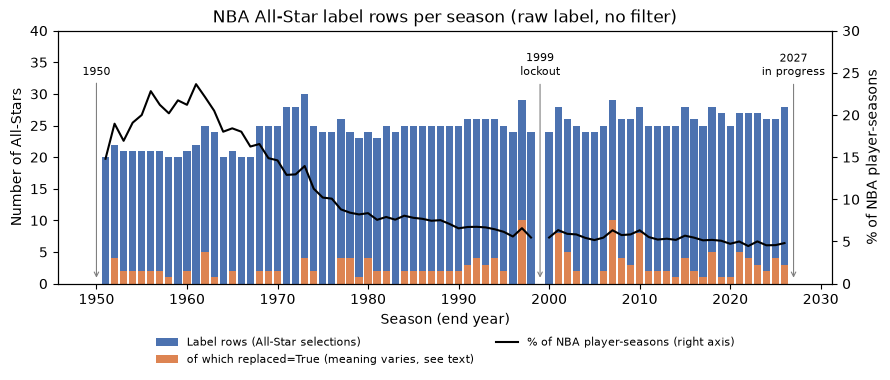

In [21]:
nba_ps = per_season[(per_season.lg == "NBA") & (per_season.n_all_star > 0)]
AUDIT["nba_all_stars_per_season"] = {"min": int(nba_ps.n_all_star.min()), "max": int(nba_ps.n_all_star.max()),
                                     "median": float(nba_ps.n_all_star.median())}
AUDIT["nba_pct_all_star_per_season"] = {"min": float(nba_ps.pct_all_star.min()), "max": float(nba_ps.pct_all_star.max()),
                                        "season_of_min": int(nba_ps.loc[nba_ps.pct_all_star.idxmin(), "season"]),
                                        "season_of_max": int(nba_ps.loc[nba_ps.pct_all_star.idxmax(), "season"])}
AUDIT["n_replaced_total"] = int(asg.replaced.sum())
print(AUDIT["nba_all_stars_per_season"], AUDIT["nba_pct_all_star_per_season"])

# Figure 2: NBA All-Stars per season and share of player-seasons
nba_all = per_season[per_season.lg == "NBA"].set_index("season")
# Seasons without any label (no All-Star Game / in progress): show a gap, not a fake 0%
rate = nba_all.pct_all_star.where(nba_all.n_all_star > 0)
fig, ax1 = plt.subplots(figsize=(9, 4.0))
ax1.bar(nba_all.index, nba_all.n_all_star, color="#4C72B0", label="Label rows (All-Star selections)")
ax1.bar(nba_all.index, nba_all.n_replaced, color="#DD8452", label="of which replaced=True (meaning varies, see text)")
ax1.set_xlabel("Season (end year)")
ax1.set_ylabel("Number of All-Stars")
ax1.set_ylim(0, 40)
ax2 = ax1.twinx()
ax2.plot(rate.index, rate.values, color="black", lw=1.5, label="% of NBA player-seasons (right axis)")
ax2.set_ylabel("% of NBA player-seasons")
ax2.set_ylim(0, 30)
for s, txt in [(1950, "1950"), (1999, "1999\nlockout"), (2027, "2027\nin progress")]:
    ax1.annotate(txt, xy=(s, 0.5), xytext=(s, 33), ha="center", fontsize=8,
                 arrowprops=dict(arrowstyle="->", lw=0.8, color="grey"))
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=8, frameon=False)
ax1.set_title("NBA All-Star label rows per season (raw label, no filter)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig2_target_per_season.png", dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()

**Why accuracy is misleading here:** the table above shows the accuracy of a model that *always predicts "not All-Star"*
(column `accuracy_always_predict_0_pct`). It is above 90% while finding zero All-Stars (recall = 0). We will therefore report
PR-AUC, precision/recall/F1 on the positive class, not accuracy.

**Injury replacements:** because the `replaced` flag is inconsistent across seasons (section above), *injured selections* and
*replacements* cannot be reliably separated with this file alone. Whether each group counts as a positive is an open decision,
and implementing either choice first requires a season-by-season check against the source.

## 5. Temporal coverage and first look at drift

{'min': 104, 'season_of_min': 1961, 'max': 812, 'season_of_max': 2022, 'n_seasons': 78}


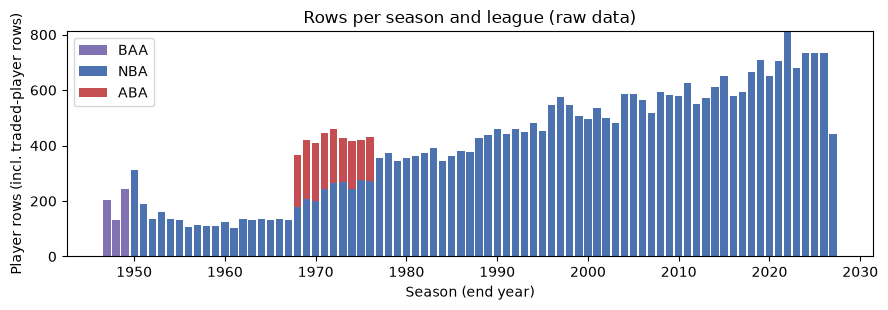

In [22]:
rows_per_season = totals.groupby(["season", "lg"]).size().unstack(fill_value=0)
nba_rows = rows_per_season["NBA"][rows_per_season["NBA"] > 0]
AUDIT["nba_rows_per_season"] = {"min": int(nba_rows.min()), "season_of_min": int(nba_rows.idxmin()),
                                "max": int(nba_rows.max()), "season_of_max": int(nba_rows.idxmax()),
                                "n_seasons": int(len(nba_rows))}
print(AUDIT["nba_rows_per_season"])

fig, ax = plt.subplots(figsize=(9, 3.2))
bottom = np.zeros(len(rows_per_season))
for lg, color in [("BAA", "#8172B3"), ("NBA", "#4C72B0"), ("ABA", "#C44E52")]:
    ax.bar(rows_per_season.index, rows_per_season[lg], bottom=bottom, color=color, label=lg)
    bottom += rows_per_season[lg].to_numpy()
ax.set_xlabel("Season (end year)")
ax.set_ylabel("Player rows (incl. traded-player rows)")
ax.set_title("Rows per season and league (raw data)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig3_rows_per_season.png", dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()

In [23]:
# Drift on 3 league-level variables, from the 'League Average' rows of the team files
# (team files avoid the traded-player question entirely)
LEAGUE_AVG = "League Average"
summ = tables["Team Summaries.csv"]
team_pg = tables["Team Stats Per Game.csv"]
lg_summ = summ[(summ.team == LEAGUE_AVG) & (summ.lg == "NBA")].set_index("season").sort_index()
lg_pg = team_pg[(team_pg.team == LEAGUE_AVG) & (team_pg.lg == "NBA")].set_index("season").sort_index()

drift = pd.DataFrame({
    "pace": lg_summ["pace"],                     # possessions per 48 minutes
    "x3pa_per_team_game": lg_pg["x3pa_per_game"],  # 3-point attempts per team per game
    "x3p_attempt_rate": lg_summ["x3p_ar"],       # share of field-goal attempts that are threes
    "pts_per_team_game": lg_pg["pts_per_game"],
})
drift.to_csv(TABLES_DIR / "drift_league_average.csv")
check_seasons = [s for s in (1980, 1990, 2000, 2010, 2020, 2026) if s in drift.index]
AUDIT["drift"] = drift.loc[check_seasons].round(3).to_dict(orient="index")
AUDIT["drift_first_season_pace"] = int(drift.pace.first_valid_index())
drift.loc[check_seasons]

,pace,x3pa_per_team_game,x3p_attempt_rate,pts_per_team_game
season,,,,
1980,103.1,2.8,0.031,109.3
1990,98.3,6.6,0.076,107.0
2000,93.1,13.7,0.167,97.5
2010,92.7,18.1,0.222,100.4
2020,100.3,34.1,0.384,111.8
2026,99.4,37.0,0.415,115.6


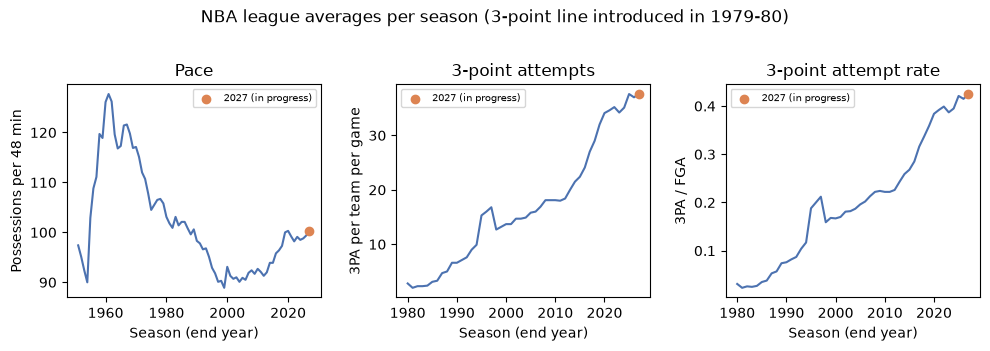

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
specs = [("pace", "Possessions per 48 min", "Pace"),
         ("x3pa_per_team_game", "3PA per team per game", "3-point attempts"),
         ("x3p_attempt_rate", "3PA / FGA", "3-point attempt rate")]
for ax, (col, ylab, title) in zip(axes, specs):
    s = drift[col].dropna()
    ax.plot(s.index, s.values, color="#4C72B0")
    if 2027 in s.index:
        ax.scatter([2027], [s.loc[2027]], color="#DD8452", zorder=3, label="2027 (in progress)")
        ax.legend(fontsize=7)
    ax.set_xlabel("Season (end year)")
    ax.set_ylabel(ylab)
    ax.set_title(title)
fig.suptitle("NBA league averages per season (3-point line introduced in 1979-80)", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig4_drift.png", dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()

## 6. Leakage screening

Every column of every file is classified by explicit rules (`src/eda/audit.py::classify_column`); the code raises an error if a
column has no rule. **SUSPECT** mostly means *depends on the prediction time*: full-season statistics include games played after
the All-Star selection (made mid-season), so they are acceptable for an end-of-season framing but leak for a mid-season framing.

In [25]:
columns_by_file = {name: df.columns.tolist() for name, df in tables.items()}
leak = audit.leakage_table(columns_by_file)
assert len(leak) == sum(len(c) for c in columns_by_file.values())  # every column classified once
leak.to_csv(TABLES_DIR / "leakage_screening.csv", index=False)

AUDIT["leakage_counts"] = leak.verdict.value_counts().to_dict()
AUDIT["leakage_n_columns"] = len(leak)
print("Columns classified:", len(leak), "|", AUDIT["leakage_counts"])

# Condensed view: one line per (verdict, reason), with the files and an example of columns
condensed = (leak.groupby(["verdict", "reason_key"])
             .agg(n_columns=("column", "size"),
                  files=("file", lambda s: ", ".join(sorted(set(f.removesuffix(".csv") for f in s)))),
                  example_columns=("column", lambda s: ", ".join(list(dict.fromkeys(s))[:6])))
             .reset_index())
condensed.to_csv(TABLES_DIR / "leakage_condensed.csv", index=False)
AUDIT["leakage_condensed"] = condensed.to_dict(orient="records")
condensed

Columns classified: 487 | {'SUSPECT': 361, 'SAFE': 94, 'LEAKY': 32}


,verdict,reason_key,n_columns,files,example_columns
0,LEAKY,career_future,2,Player Career Info,"to, hof"
1,LEAKY,label_meta,2,All-Star Selections,"team, replaced"
2,LEAKY,playoffs,8,"Opponent Stats Per 100 Poss, Opponent Stats Pe...",playoffs
3,LEAKY,post_season,20,"End of Season Teams, End of Season Teams (Voti...","type, number_tm, position, age, pts_won, pts_max"
4,SAFE,key,41,"Advanced, All-Star Selections, Draft Pick Hist...","season, lg"
5,SAFE,pre_season,37,"Advanced, Draft Pick History, Opponent Stats P...","age, pos, overall_pick, round, tm, college"
6,SAFE,team_code,16,"Advanced, Opponent Stats Per 100 Poss, Opponen...",team
7,SUSPECT,attendance,2,Team Summaries,"attend, attend_g"
8,SUSPECT,games,14,"Advanced, Per 100 Poss, Per 36 Minutes, Player...","g, gs"
9,SUSPECT,identity,28,"Advanced, All-Star Selections, Draft Pick Hist...","player, player_id"


In [26]:
# The LEAKY columns, listed explicitly
leak[leak.verdict == "LEAKY"].groupby("file").column.apply(list).to_frame("LEAKY columns")

,LEAKY columns
file,
All-Star Selections.csv,"[team, replaced]"
End of Season Teams (Voting).csv,"[type, number_tm, position, age, pts_won, pts_..."
End of Season Teams.csv,"[type, number_tm, position]"
Opponent Stats Per 100 Poss.csv,[playoffs]
Opponent Stats Per Game.csv,[playoffs]
Opponent Totals.csv,[playoffs]
Player Award Shares.csv,"[award, age, first, pts_won, pts_max, share, w..."
Player Career Info.csv,"[to, hof]"
Team Abbrev.csv,[playoffs]


## 7. Save every number quoted in the report

In [27]:
AUDIT["generated_by"] = "notebooks/01_dataset_audit.ipynb"
AUDIT["versions"] = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__}
AUDIT_NUMBERS_PATH.write_text(json.dumps(audit.to_builtin(AUDIT), indent=2), encoding="utf-8")
print("Saved", AUDIT_NUMBERS_PATH.relative_to(PROJECT_ROOT), "with keys:", list(AUDIT))

Saved report\audit_numbers.json with keys: ['source', 'shapes', 'n_player_rows', 'season_min', 'season_max', 'rows_by_league', 'label_rows', 'label_rows_by_league', 'label_season_min', 'label_season_max', 'player_tables_same_row_keys', 'missing_structural', 'unexplained_missing_NBA_1980_2026', 'first_recorded_season_NBA', 'exact_duplicate_rows_total', 'traded', 'n_player_seasons', 'traded_share_pct_by_decade', 'ids_with_several_names', 'names_shared_by_several_ids', 'player_seasons_in_two_leagues', 'label_duplicate_keys', 'label_rows_without_stats', 'replaced_flag', 'seasons_without_label', 'season_2027', 'season_1999', 'labelled_seasons_in_window', 'class_balance', 'nba_all_stars_per_season', 'nba_pct_all_star_per_season', 'n_replaced_total', 'nba_rows_per_season', 'drift', 'drift_first_season_pace', 'leakage_counts', 'leakage_n_columns', 'leakage_condensed', 'generated_by', 'versions']
